<a href="https://colab.research.google.com/github/Elliotn46/27-13001506-DE-JS-Assesment/blob/main/seismic_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install obspy ipython-sql sqlalchemy folium pandas matplotlib adjustText

import os
import obspy
import sqlite3
from obspy.clients.fdsn import Client
import pandas as pd
import matplotlib.pyplot as plt
import folium


os.makedirs("database", exist_ok=True)
os.makedirs("data", exist_ok=True)
%load_ext sql
%sql sqlite:///database/seismic.db

In [2]:
%%sql
--Stations Table
CREATE TABLE IF NOT EXISTS stations (
    network TEXT NOT NULL,
    station TEXT NOT NULL,
    latitude REAL NOT NULL,
    longitude REAL NOT NULL,
    elevation REAL,
    PRIMARY KEY (network, station)
);

--Channels Table
CREATE TABLE IF NOT EXISTS channels (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    network TEXT NOT NULL,
    station TEXT NOT NULL,
    location TEXT NOT NULL,
    channel TEXT NOT NULL,
    sampling_rate REAL NOT NULL,
    FOREIGN KEY (network, station) REFERENCES stations (network, station) ON DELETE CASCADE,
    UNIQUE (network, station, location, channel)
);

--Waveform Headers / Metadata Table
CREATE TABLE IF NOT EXISTS waveforms (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    channel_id INTEGER NOT NULL,
    starttime TEXT NOT NULL,
    endtime TEXT NOT NULL,
    npts INTEGER NOT NULL,
    file_source TEXT NOT NULL,
    FOREIGN KEY (channel_id) REFERENCES channels (id) ON DELETE CASCADE
);

 * sqlite:///database/seismic.db
Done.
Done.
Done.


[]

In [3]:
# Initialize SQLite database
db_path = "database/seismic.db"
conn = sqlite3.connect(db_path)
cursor = conn.cursor()

# Execute schema creation
cursor.execute('''CREATE TABLE IF NOT EXISTS stations (network TEXT, station TEXT, latitude REAL, longitude REAL, elevation REAL, PRIMARY KEY (network, station));''')
cursor.execute('''CREATE TABLE IF NOT EXISTS channels (id INTEGER PRIMARY KEY AUTOINCREMENT, network TEXT, station TEXT, location TEXT, channel TEXT, sampling_rate REAL);''')
conn.commit()

# Load mseed files
mseed_files = ["/SEP01.mseed", "/SEP02.mseed", "/SEP03.mseed"]
iris_client = Client("EARTHSCOPE")

# Track discovered stations to query IRIS once
discovered_stations = set()

for file_path in mseed_files:
    if os.path.exists(file_path):
        st = obspy.read(file_path, format="MSEED")

        # Insert station metadata
        for tr in st:
            net, sta, loc, cha = tr.stats.network, tr.stats.station, tr.stats.location, tr.stats.channel
            discovered_stations.add((net, sta))

            # Insert channel metadata
            cursor.execute('''INSERT OR IGNORE INTO channels (network, station, location, channel, sampling_rate) VALUES (?, ?, ?, ?, ?)''',
                           (net, sta, loc, cha, tr.stats.sampling_rate))
        conn.commit()

print(f"Processed miniSEED files. Discovered stations from data: {discovered_stations}")

Processed miniSEED files. Discovered stations from data: {('CC', 'SEP')}


In [4]:
import obspy
import sqlite3
import os

db_path = "database/seismic.db"
mseed_files = ["/SEP01.mseed", "/SEP02.mseed", "/SEP03.mseed"]

with sqlite3.connect(db_path) as conn:
    cursor = conn.cursor()

    # Enforce foreign keys in SQLite
    cursor.execute("PRAGMA foreign_keys = ON;")

    for file_path in mseed_files:
        if not os.path.exists(file_path):
            print(f"⚠️ Skipping {file_path} (not found)")
            continue

        st = obspy.read(file_path)

        for tr in st:
            stats = tr.stats
            net = stats.network
            sta = stats.station
            loc = stats.location
            cha = stats.channel
            sampling_rate = stats.sampling_rate
            start_time = str(stats.starttime)
            end_time = str(stats.endtime)
            npts = stats.npts

            # 1. Insert into stations (uses composite PK: network, station)
            cursor.execute("""
                INSERT OR IGNORE INTO stations (network, station, latitude, longitude, elevation)
                VALUES (?, ?, ?, ?, ?)
            """, (net, sta, 0.0, 0.0, 0.0))

            # 2. Insert into channels (references network and station)
            cursor.execute("""
                INSERT OR IGNORE INTO channels (network, station, location, channel, sampling_rate)
                VALUES (?, ?, ?, ?, ?)
            """, (net, sta, loc, cha, sampling_rate))

            # Fetch the auto-incremented channel id
            cursor.execute("""
                SELECT id FROM channels
                WHERE network = ? AND station = ? AND location = ? AND channel = ?
            """, (net, sta, loc, cha))

            channel_row = cursor.fetchone()
            if not channel_row:
                continue
            channel_id = channel_row[0]

            # 3. Insert into waveforms (matches your table definition)
            cursor.execute("""
                INSERT INTO waveforms (channel_id, starttime, endtime, npts, file_source)
                VALUES (?, ?, ?, ?, ?)
            """, (channel_id, start_time, end_time, npts, os.path.basename(file_path)))

    conn.commit()

print("✅ Database successfully populated!")

✅ Database successfully populated!


In [5]:
import os
import sqlite3
import pandas as pd
import obspy
from obspy.clients.fdsn import Client
import matplotlib.pyplot as plt

print("=" * 60)
print(" 1. METADATA SUMMARY")
print("=" * 60)

db_path = "database/seismic.db"
with sqlite3.connect(db_path) as conn:
    df_waveforms = pd.read_sql_query("""
        SELECT c.network, c.station, c.location, c.channel, w.starttime, w.endtime, w.npts, w.file_source
        FROM waveforms w
        JOIN channels c ON w.channel_id = c.id
    """, conn)
    display(df_waveforms)





 1. METADATA SUMMARY


,network,station,location,channel,starttime,endtime,npts,file_source
0,CC,SEP,--,EHZ,2023-11-11T00:00:00.000001Z,2023-11-11T00:36:58.090001Z,221810,SEP01.mseed
1,CC,SEP,--,EHZ,2023-11-11T00:37:45.100001Z,2023-11-11T01:41:06.090001Z,380100,SEP01.mseed
2,CC,SEP,--,EHZ,2023-11-11T01:43:07.100001Z,2023-11-11T02:01:05.090001Z,107800,SEP01.mseed
3,CC,SEP,--,EHZ,2023-11-11T02:01:47.100001Z,2023-11-11T02:02:10.090001Z,2300,SEP01.mseed
4,CC,SEP,--,EHZ,2023-11-11T02:02:24.100001Z,2023-11-11T02:17:01.090001Z,87700,SEP01.mseed
...,...,...,...,...,...,...,...,...
59,CC,SEP,--,EHZ,2023-11-25T17:22:09.600001Z,2023-11-25T17:54:47.590001Z,195800,SEP03.mseed
60,CC,SEP,--,EHZ,2023-11-25T17:55:35.600001Z,2023-11-25T20:41:11.590001Z,993600,SEP03.mseed
61,CC,SEP,--,EHZ,2023-11-25T20:42:14.600001Z,2023-11-25T21:42:03.590001Z,358900,SEP03.mseed
62,CC,SEP,--,EHZ,2023-11-25T21:42:16.600001Z,2023-11-25T23:17:25.590001Z,570900,SEP03.mseed



 2. GENERATING HELICORDER PLOT
Plotting helicorder for: /SEP01.mseed


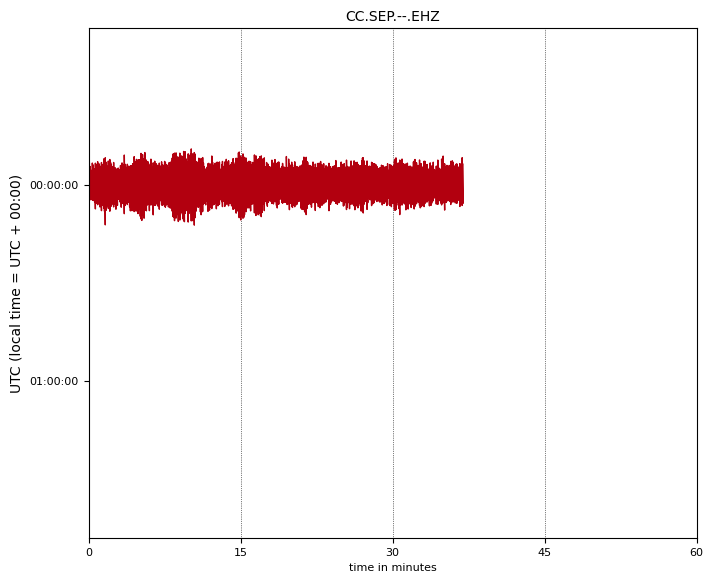

Plotting helicorder for: /SEP02.mseed


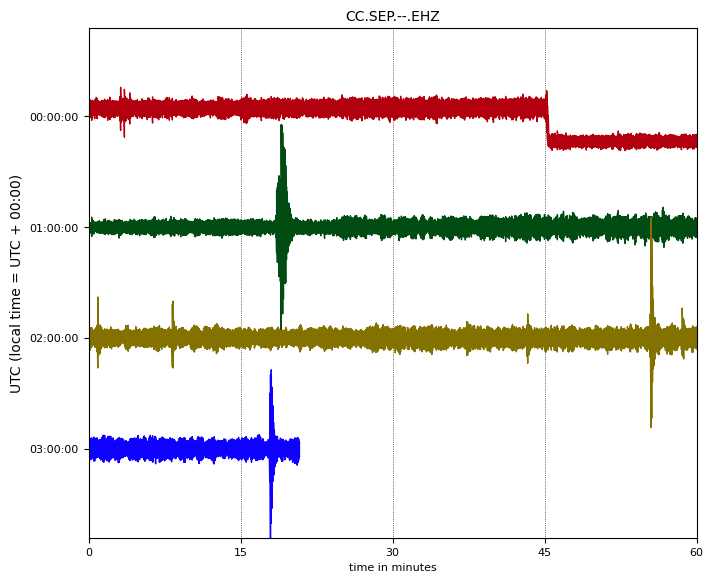

Plotting helicorder for: /SEP03.mseed


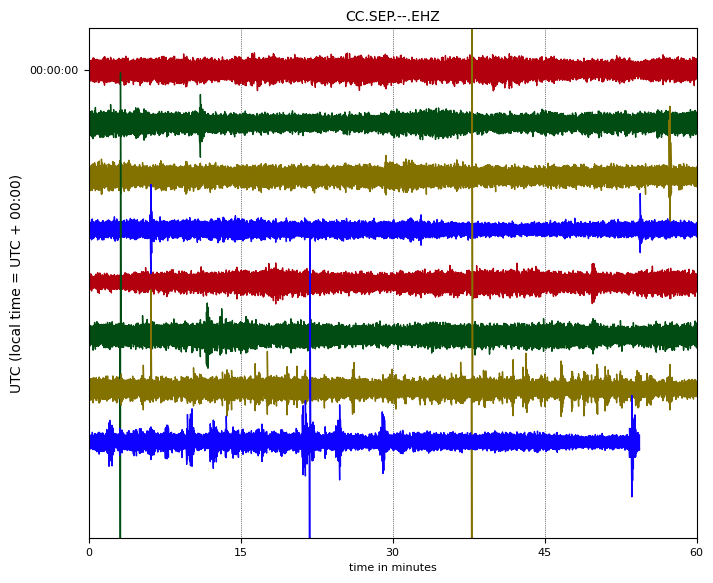

In [6]:
print("\n" + "=" * 60)
print(" 2. GENERATING HELICORDER PLOT")
print("=" * 60)

mseed_files = ["/SEP01.mseed", "/SEP02.mseed", "/SEP03.mseed"]

for file_path in mseed_files:
  if os.path.exists(file_path):
      st = obspy.read(file_path)
      print(f"Plotting helicorder for: {file_path}")

      # ObsPy built-in dayplot creates a classic stacked helicorder view
      fig = st[0].plot(type="dayplot", interval=60, right_stream_id=True, show=True)
      plt.show()
  else:
      print(f"⚠️ Warning: {file_path} not found for helicorder plotting.")


 3. FETCHING IRIS STATION METADATA & STATIC MAP
Querying IRIS API for stations: ['SUG', 'HOA', 'SEP']


,network,station,latitude,longitude,elevation,site_name
0,CC,SUG,46.215549,-122.176262,1859.0,Sugar Bowl
1,SY,SUG,46.215549,-122.176262,1859.0,SUG synthetic
2,UW,SUG,46.215549,-122.176262,1859.0,Sugar Bowl
3,CC,HOA,46.241780,-122.191830,1151.0,Hoala
4,SY,HOA,46.241779,-122.191833,1151.0,HOA synthetic
5,CC,SEP,46.199780,-122.190857,2114.0,"September lobe, Mt. St. Helens (Dome sta)"
6,SY,SEP,48.073681,-123.048058,45.0,SEP synthetic
7,UW,SEP,46.200211,-122.190598,2116.0,"September lobe, Mt. St. Helens (Dome sta)"


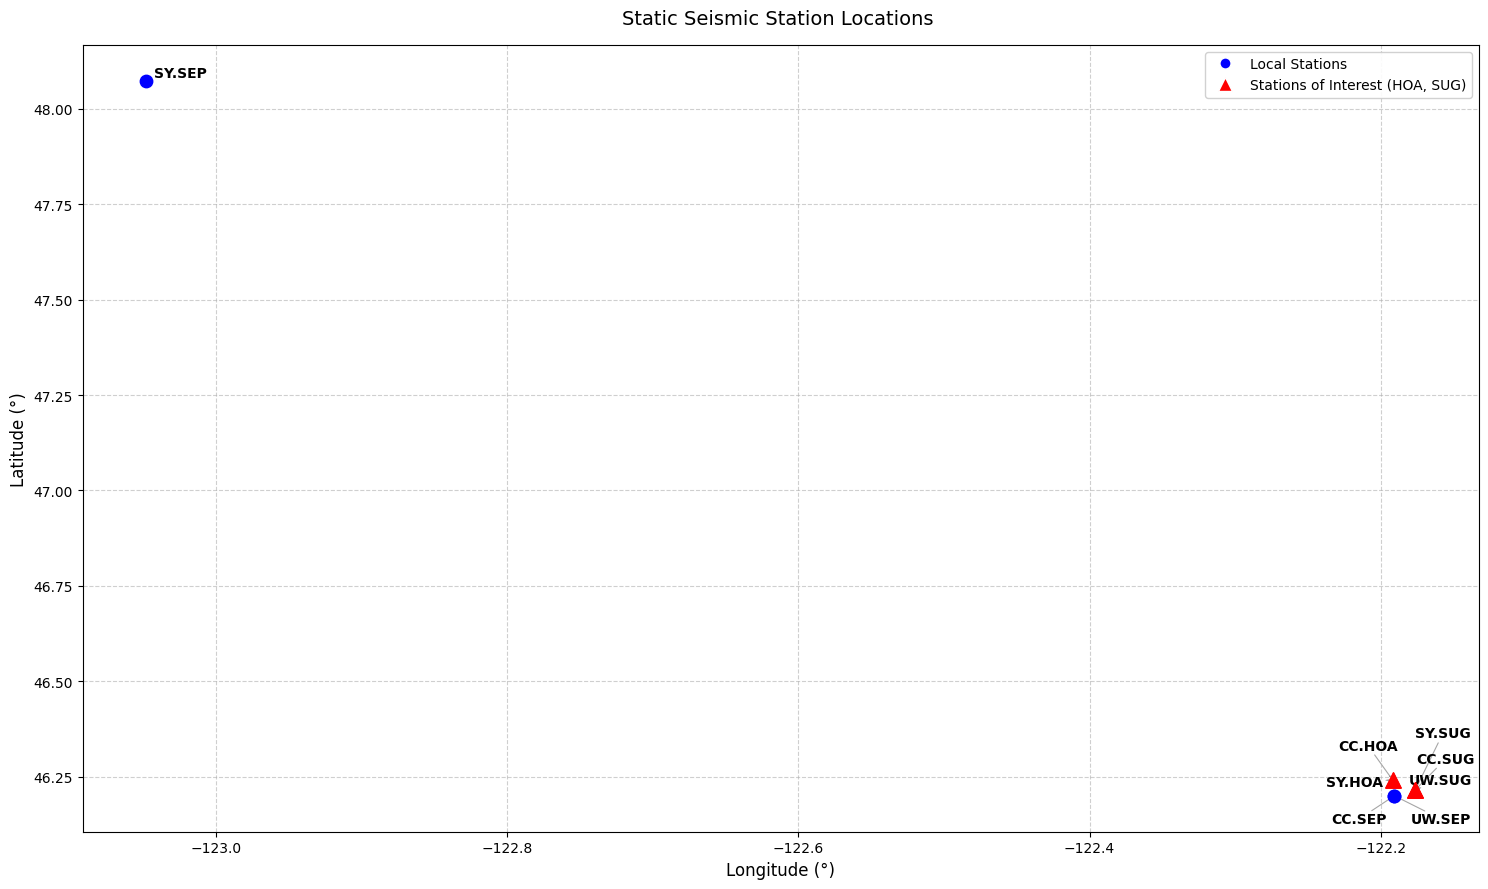

In [16]:
from adjustText import adjust_text
from matplotlib.lines import Line2D

print("\n" + "=" * 60)
print(" 3. FETCHING IRIS STATION METADATA & STATIC MAP")
print("=" * 60)

client = Client("EARTHSCOPE")

# Get stations from SQLite database
with sqlite3.connect(db_path) as conn:
    cursor = conn.cursor()
    cursor.execute("SELECT DISTINCT station FROM stations")
    db_stations = [row[0] for row in cursor.fetchall()]

# Combine local stations with target stations of interest (HOA, SUG)
target_stations = list(set(db_stations + ["HOA", "SUG"]))
print(f"Querying IRIS API for stations: {target_stations}")

station_records = []

for sta in target_stations:
    try:
        inv = client.get_stations(station=sta, level="station")
        for net in inv:
            for s in net:
                station_records.append({
                    'network': net.code,
                    'station': s.code,
                    'latitude': s.latitude,
                    'longitude': s.longitude,
                    'elevation': s.elevation,
                    'site_name': s.site.name if s.site else "Unknown"
                })
    except Exception as e:
        print(f"Could not fetch metadata for station {sta} from IRIS: {e}")

df_stations_map = pd.DataFrame(station_records)
display(df_stations_map)

# --- MAP GENERATION ---
if not df_stations_map.empty:
    plt.figure(figsize=(15, 9))
    texts = []

    # Plot all stations
    for idx, row in df_stations_map.iterrows():
        is_target = row['station'] in ['HOA', 'SUG']
        color = 'red' if is_target else 'blue'
        marker = '^' if is_target else 'o'
        size = 120 if is_target else 80

        plt.scatter(row['longitude'], row['latitude'], color=color, marker=marker, s=size, zorder=5, label=row['station'])
        t = plt.text(
          row['longitude'],
          row['latitude'],
          f"{row['network']}.{row['station']}",
          fontsize=10,
          fontweight='bold'
        )
        texts.append(t)

    adjust_text(
    texts,
    arrowprops=dict(arrowstyle='->', color='gray', lw=0.8, alpha=0.7),
    force_text=(0.5, 1.0)
    )
    plt.xlabel("Longitude (°)", fontsize=12)
    plt.ylabel("Latitude (°)", fontsize=12)
    plt.title("Static Seismic Station Locations ", fontsize=14, pad=15)
    plt.grid(True, linestyle='--', alpha=0.6)

    # Add clean legend
    legend_elements = [
    Line2D([0], [0], marker='o', color='w', label='Local Stations',
           markerfacecolor='blue', markersize=8),
    Line2D([0], [0], marker='^', color='w', label='Stations of Interest (HOA, SUG)',
           markerfacecolor='red', markersize=10)
    ]

    plt.legend(handles=legend_elements, loc='upper right', frameon=True, facecolor='white', framealpha=0.9)

    plt.tight_layout()
    plt.show()
else:
    print("⚠️ No station coordinates available to plot.")